# SuperStore - Business Review
* Data cleaning and Exploration
* Correlation matrix
* Customer segmentation


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)



### Import the dataset
Import the data and gather insights of what the data looks like

In [12]:
df = pd.read_csv("Sample - Superstore.csv",encoding='latin1')
print (df.shape)
print (df.info())
print (df.describe())



(9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 1

In [13]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


### Split the dataset into numerical and categorical values
* Transform dates to numerical types
* Split the dataset

In [14]:
# Transform date to numerical types
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [15]:
num = df[["Sales", "Quantity", "Discount", "Profit"]]
cat = df[['Row ID', 'Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment','Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [16]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [17]:
round(num.describe(), 2)

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [18]:
#Overal sales and profit by Category
Category= df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Avg_Sales=('Sales','mean'),
    Avg_Profit=('Profit','mean')).reset_index().round(2)
print(Category)


          Category  Total_Sales  Total_Profit  Avg_Sales  Avg_Profit
0        Furniture    741999.80      18451.27     349.83        8.70
1  Office Supplies    719047.03     122490.80     119.32       20.33
2       Technology    836154.03     145454.95     452.71       78.75


## Super Store

This dataset contains information about customers from SuperStore  and their purchases, aiming to analyze the relationships between different features and the target variable, `Sales`. 

### Key Features:
- **Customer Characteristics**: Information about customer (`Customer ID`, `Customer Name`,`Segment`, `City`,etc.).
- **Order Details**: Information about the order (`Order ID`, `Order Date`).
- **Shipment Details**: Shipment details (`Ship Date`, `Ship Mode`).
- **Product Information**: Productcategory and productname (`Category`, `Sub-Category`, `Product Name`, etc.).
- **Sale Information**: Sale quantity, Sales revenue, discount and profit (`Sales`, `Quantity`, `Discount`, `Profit`.).

### Summary:
- **Total Features**: 19 (combination of numerical and categorical variables).
- **Target Variable**: `Sales` (in USD).

### Crosstab
A table showing the frequency of occurrences for combinations of two categorical variables.

For this business review the focus will be on the different regions and the products. 
Therefore the we will look first into 
* Region and Category
* Sub-Category and Ship mode
* State and Segment
* Segment and Discount

First we will define these variables 

In [19]:
segment = cat['Segment']
category = cat['Category']
ship = cat['Ship Mode']
subcat = cat['Sub-Category']
region = cat['Region']
state = cat['State']
discount = num['Discount']
sales = num['Sales']
profit = num['Profit']
segment.unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

### Region And Category

In [20]:
crosstab_result = pd.crosstab(region, category)
crosstab_result

Category,Furniture,Office Supplies,Technology
Region,,,
Central,481,1422,420
East,601,1712,535
South,332,995,293
West,707,1897,599


**Interpretation of Region vs. Category**

Out of the all categories: 
* Majority of the orders comes from West
* Least orders come from South
* Majority of the orders are from the category Office Supplies
* Technology is the smallest category over all the regions

However the division between regions don't tell me that much. So I would like to see which states belong in these regions



In [21]:
region_state_table = df[["Region", "State"]].drop_duplicates().sort_values(by="Region")
print(region_state_table)

       Region                 State
44    Central             Minnesota
158   Central              Oklahoma
49    Central               Indiana
46    Central              Michigan
144   Central              Missouri
41    Central              Illinois
21    Central              Nebraska
111   Central                  Iowa
16    Central             Wisconsin
14    Central                 Texas
2313  Central          South Dakota
4362  Central          North Dakota
1794  Central                Kansas
1020     East  District of Columbia
2234     East               Vermont
2255     East                 Maine
887      East              Maryland
871      East         New Hampshire
395      East          Rhode Island
346      East         Massachusetts
197      East            New Jersey
185      East           Connecticut
113      East                  Ohio
7894     East         West Virginia
23       East          Pennsylvania
47       East              Delaware
53       East              N

### Sub-Category vs. Shipment
It might be interesting to see if a specific shipment mode is chosen in certain categories, that might impact profitability. 

In [22]:
crosstab_result2 = pd.crosstab(subcat, ship)
crosstab_result2

Ship Mode,First Class,Same Day,Second Class,Standard Class
Sub-Category,,,,
Accessories,128,41,162,444
Appliances,76,23,79,288
Art,112,36,155,493
Binders,239,74,263,947
Bookcases,49,7,48,124
Chairs,85,39,134,359
Copiers,12,5,15,36
Envelopes,32,14,53,155
Fasteners,30,14,37,136


**Interpretation of Sub-Category and Shipment**

An assumption is that smaller items would use different modes of transport than bigger items. 
however it is seen that in volume the biggest shipment mode used is the standard class. 


### Customer behaviour
The next crosstabs will show an overview of sales and how the discount is used: 
* Region/Segment
* Sub-Category/ Region


In [23]:
crosstab_segment_sales = pd.crosstab(segment, region, values=sales, aggfunc="sum").round(2)
crosstab_segment_sales

Region,Central,East,South,West
Segment,,,,
Consumer,252031.43,350908.17,195580.97,362880.77
Corporate,157995.81,200409.35,121885.93,225855.27
Home Office,91212.64,127463.73,74255.00,136721.78


In [24]:
crosstab_segment_discount = pd.crosstab(segment, region, values=discount, aggfunc="mean").round(3)
crosstab_segment_discount

Region,Central,East,South,West
Segment,,,,
Consumer,0.252,0.147,0.142,0.108
Corporate,0.240,0.144,0.158,0.114
Home Office,0.209,0.141,0.143,0.107


In [25]:
crosstab_segment_profit = pd.crosstab(segment, region, values=profit, aggfunc="sum").round(2)
crosstab_segment_profit

Region,Central,East,South,West
Segment,,,,
Consumer,8564.05,41190.98,26913.57,57450.60
Corporate,18703.90,23622.58,15215.22,34437.43
Home Office,12438.41,26709.22,4620.63,16530.42


In [26]:
crosstab_category_discount = pd.crosstab(subcat, region, values=discount, aggfunc="mean")
crosstab_category_discount

Region,Central,East,South,West
Sub-Category,,,,
Accessories,0.124590,0.085437,0.085938,0.036434
Appliances,0.448780,0.073016,0.111111,0.030882
Art,0.122727,0.069298,0.101408,0.031200
Binders,0.509290,0.353409,0.375610,0.281741
Bookcases,0.232800,0.220000,0.100000,0.228750
Chairs,0.192857,0.150595,0.097727,0.200000
Copiers,0.112500,0.250000,0.085714,0.144000
Envelopes,0.128814,0.081081,0.074074,0.041791
Fasteners,0.134545,0.091803,0.082759,0.033333


### Interpretation of Discount
Between the segments and regions:

* Most discount is given to Central Consumers, with an average discount of 0.25
* Least discount is given to West Home Office, with an average discount of 0.10

Between the Sub-Category and region:

* The Central region orders receive most discount on Binders, with an average discount of 0.50
* Followed by Appliances and Furnishings. 
* Least discount overal is given to Labels, to orders from the West region with an average discount of 0.01

Interesting that between the different segments the discount don't show too much differences. The difference is mostly visible between the regions. 

### Stacked and Grouped barcharts

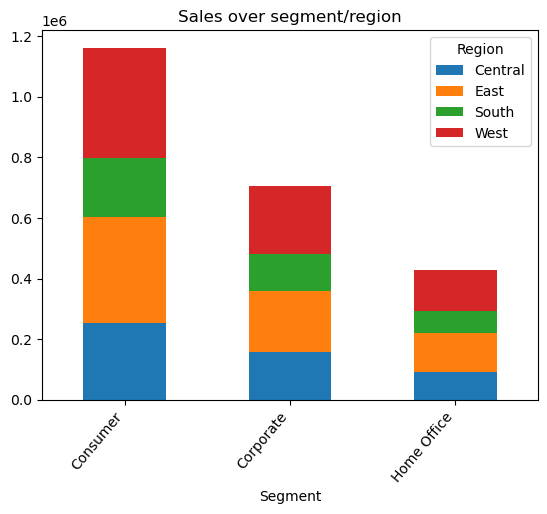

In [27]:
crosstab_segment_sales.plot(kind='bar', stacked=True)
plt.xticks(rotation=50, ha='right')
plt.title('Sales over segment/region')
plt.show()

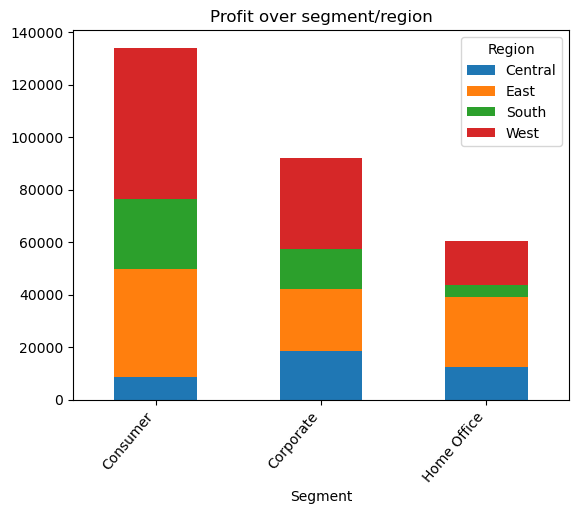

In [28]:
crosstab_segment_profit.plot(kind='bar', stacked=True)
plt.xticks(rotation=50, ha='right')
plt.title('Profit over segment/region')
plt.show()

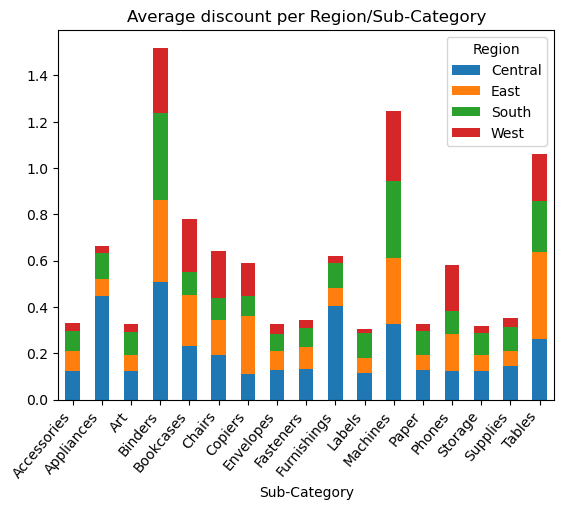

In [29]:
crosstab_category_discount.plot(kind='bar', stacked=True)
plt.xticks(rotation=50, ha='right')
plt.title('Average discount per Region/Sub-Category')
plt.show()

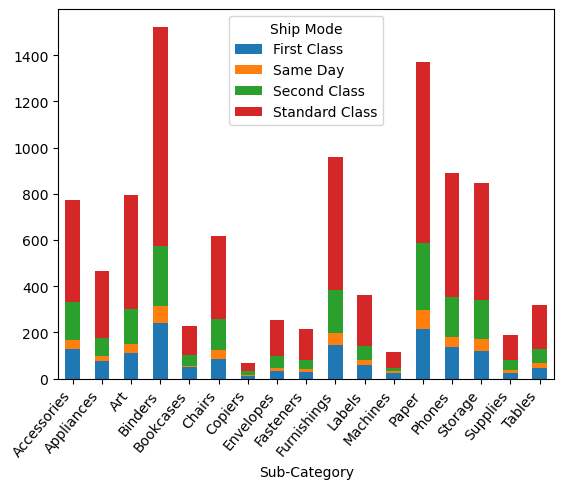

In [30]:
crosstab_result2.plot(kind='bar', stacked=True)
plt.xticks(rotation=50, ha='right')
plt.show()

### Overal Sales & Profit of Superstore

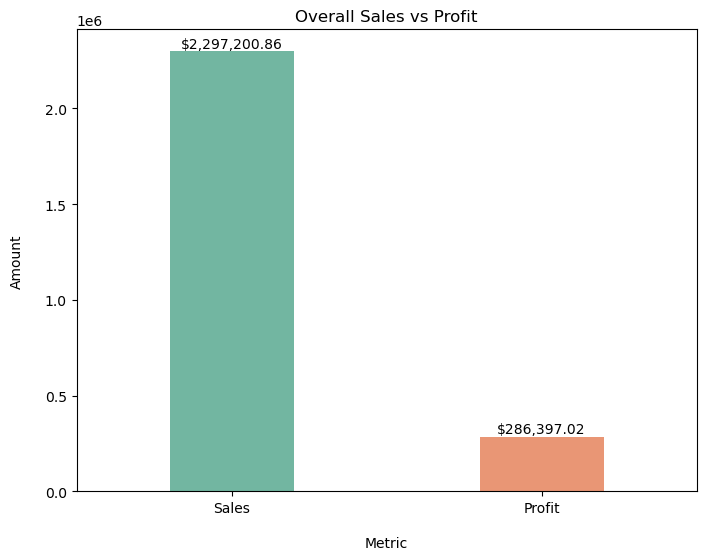

In [31]:
plot_df = df[['Sales', 'Profit']].sum().reset_index().round(2)
plot_df.columns = ['Metric', 'Amount']

plt.figure(figsize=(8,6))
plot =sns.barplot(x='Metric', y='Amount', data=plot_df,hue='Metric', palette='Set2', width=0.4)

for p in plot.patches:
    plot.annotate(f"${p.get_height():,.2f}",
                  (p.get_x() + p.get_width()/2, p.get_height()),
                  ha='center', va='bottom')

plt.title('Overall Sales vs Profit')
plt.xlabel('Metric', labelpad=15)
plt.ylabel('Amount', labelpad=15)
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_18708\2345207787.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sub-Category", y="Sales", order=sorted_order, estimator="sum", palette="coolwarm", errorbar=None)


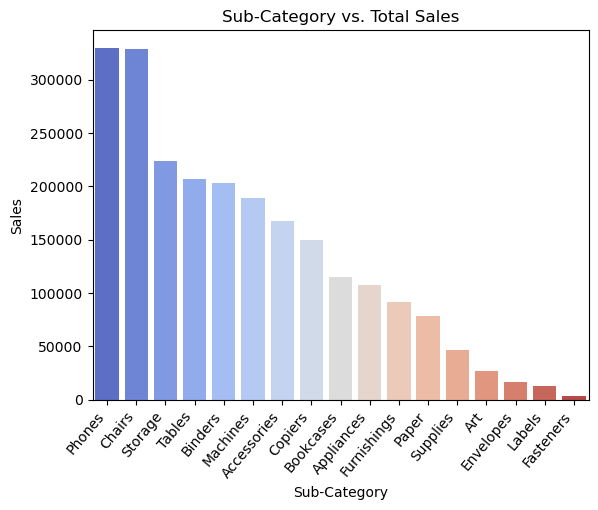

In [63]:
sorted_order = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).index
sns.barplot(data=df, x="Sub-Category", y="Sales", order=sorted_order, estimator="sum", palette="coolwarm", errorbar=None)
plt.xticks(rotation=50, ha='right')
plt.title('Sub-Category vs. Total Sales')
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_18708\425624026.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sub-Category", y="Profit", estimator="sum", palette="coolwarm", errorbar=None)


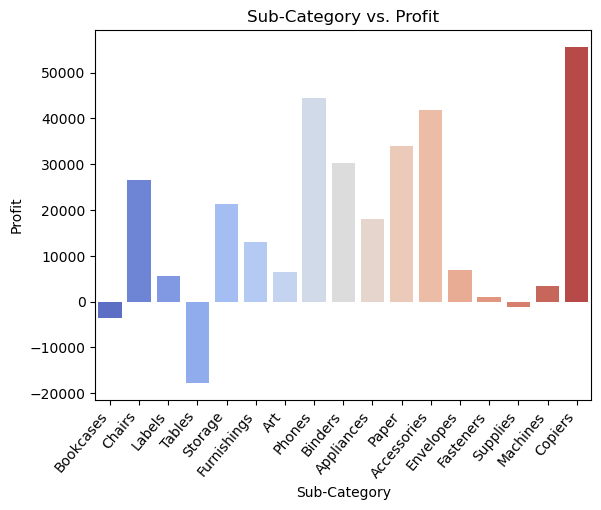

In [64]:
sns.barplot(data=df, x="Sub-Category", y="Profit", estimator="sum", palette="coolwarm", errorbar=None)
plt.xticks(rotation=50, ha='right')
plt.title('Sub-Category vs. Profit')
plt.show()

**Insights Sales Performance**

*Sales&Profit*

Over the 3 year period Superstore has generated $2.297.200,86 USD in Sales and $286.394,02 USD in profit. 

*Sub-Category*

As can be seen in the graph above, the majority of the orders are from Sub-Categories Phones, Chairs and Storage. However if we look to profit, Copiers really stand-out here. And even though Tables are the 4th best Sub-Category in Sales, it’s generating negative profit. 



### Side by side Box Plots

To get a better view of the spread of the data boxplots will be created. To check on outliers for instance on profit & sales:
* Profit over the segments
* Profit over the sub-categories
* Sales over the segments
* Sales over the sub-categories

Let's visualize the distribution of `Sales` and `Profit` for each segment and sub-category using side-by-side box plots. This will help us understand the spread, median, and potential outliers for each category.

<function matplotlib.pyplot.show(close=None, block=None)>

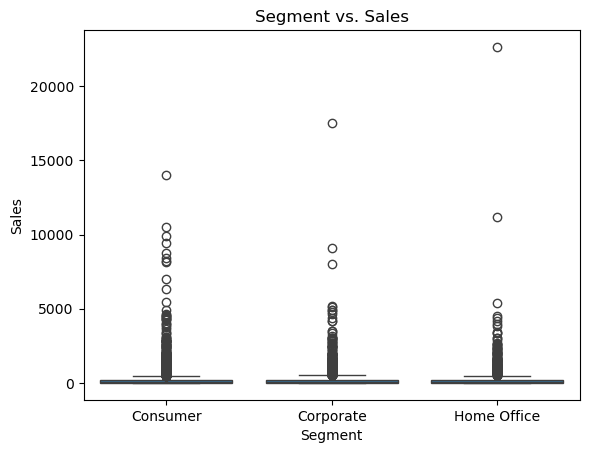

In [34]:
sns.boxplot(
    data=df,
    x='Segment',
    y='Sales',
    )
plt.title('Segment vs. Sales')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

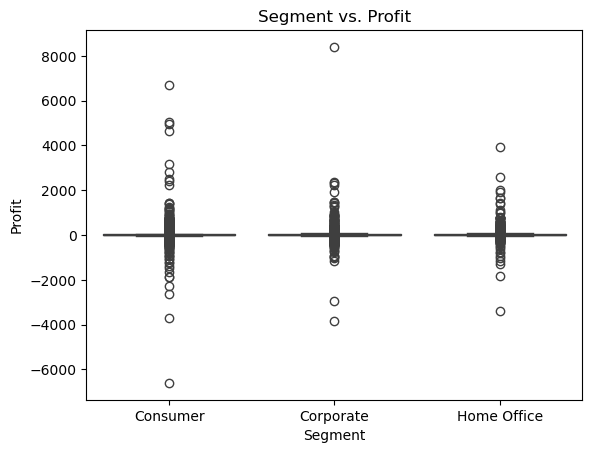

In [35]:
sns.boxplot(
    data=df,
    x='Segment',
    y='Profit',
    )
plt.title('Segment vs. Profit')
plt.show

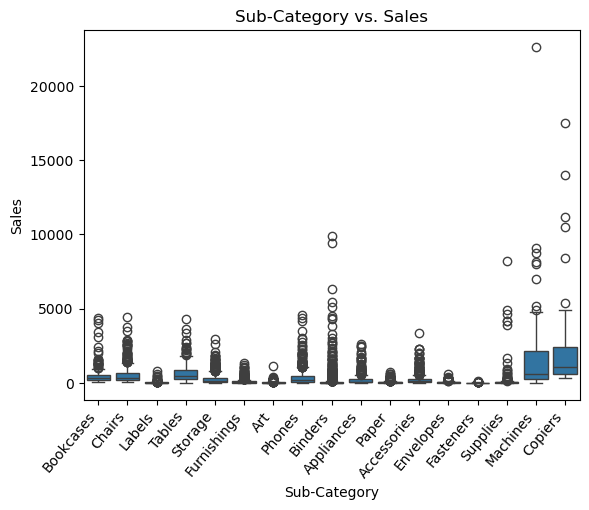

In [68]:
sns.boxplot(
    data=df,
    x='Sub-Category',
    y='Sales',
    )
plt.xticks(rotation=50, ha='right')
plt.title('Sub-Category vs. Sales')
plt.show()

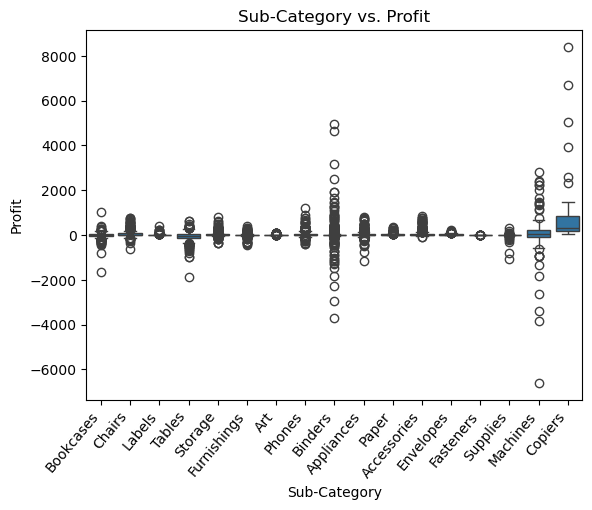

In [69]:
sns.boxplot(
    data=df,
    x='Sub-Category',
    y='Profit',
    )
plt.xticks(rotation=50, ha='right')
plt.title('Sub-Category vs. Profit')
plt.show()

**Segment**
* All three segments `Consumer`, `Corporate`, `Home Office`, have a very small box, where the median `Sales` is very similar. And all show outliers upwards. With the highest outlier at Home Office. 
* The boxplot of `Profit` with these segments also shows a very small box. With `Consumer` having both positive as negative outliers. `Corporate`, shows one extreme outlier, but the spread here is more compact. `Home Office` doesn't show the same extremities within the outliers. This shows more stability within the segments Corporate and Home Office. Where segment `consumer`shows more volatile behaviour. 

**Sub-Category & Sales**
* Sub-Categories `Machines` and `Copiers` show the highest median. Machines and Copiers typically generate higher `Sales` per order. 
* Both show extreme positive outliers. 
* Sub-Category `Binders` show the most extreme variability with frequent high outliers. 
* Sub-Categories `Labels`, `Fasteners` and `Envelopes` show very little spread, close to the axis. This is likely because these are low-cost, high-frequency items with a narrow price range. 

**Sub-Category & Profit**
* Sub-Categories `Machines`, `Binders` and `Copiers` show the highest positive outliers on profit. Binders and machines also show negative outliers, which is interesting to dive deeper into. Copiers however show only positve outliers. We can state that `Copiers`is by far the most profitable sub-category. 
* `Bookcases`, `Tables`and `Supplies` tend to show more negative outliers. Which is an indication to dive deeper into, for scaling down in certain products here. 
* Sub-Category `Phones` and `Accessories` are given the mainly positive outliers interesting to dive deeper into, to scale up. 


### Correlation 

In the next steps there will be explored whether there's a correlation between two variables. 
We will start with the method in Pandas, where a correlation matrix will be given. 

We'll begin by calculating the Pearson correlation coefficient. Which measures the **linear** relationship between two continuous variables. Where each value ranges from -1 to 1. The closer to 0, the smaller the correlation. 

Followed by the Spearman correlation efficient. Which is a **rank-based** measure of correlation. Where values range from **-1 to 1**

**Correlation matrix of the numerical values of Super Store**

In [38]:
correlation_matrix = num.corr()
correlation_matrix

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.200795,-0.028190,0.479064
Quantity,0.200795,1.000000,0.008623,0.066253
Discount,-0.028190,0.008623,1.000000,-0.219487
Profit,0.479064,0.066253,-0.219487,1.000000


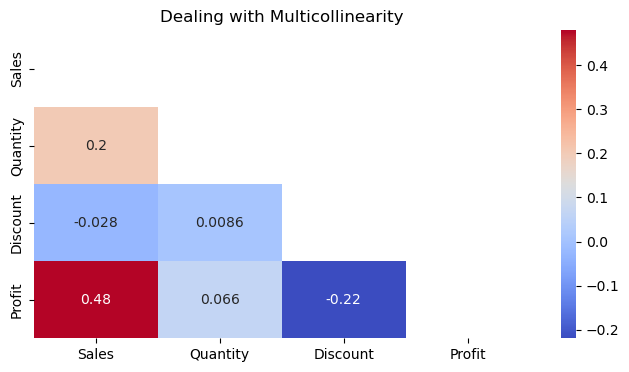

In [39]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(8, 4))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Dealing with Multicollinearity")
plt.show()

**Insights:**
* **Moderate Positive correlation** Variables `Profit` and `Sales` have a strong positive correlation. This suggests that high sales will lead to (more) profit. 
* **Negative correlation** Variables `Discount` and `Profit` show a negative correlation, however this is not as high as I expected. 
* **Discount** the variable `Discount` doesn't show an expected positive correlation with `Sales`. This could indicate that a discount would not lead to more sales. 
* **Multicollinearity** None of the variables show a correlation strong enough (usually > 0.7- 0.8) to indicate multicollinearity.

# Discount vs Sales & Profit

Next steps the correlation between discounts and Sales will be further explored. 
* Pearson & Spearman relation
* Differences between the different Sub-Categories. 

In [40]:
pearson_discount = round(float(df["Discount"].corr(df["Sales"], method="pearson")), 2)
spearman_discount = round(float(df["Discount"].corr(df["Sales"], method="spearman")), 2)

print(f"Pearson Discount & Sales: {pearson_discount}")
print(f"Spearman Discount & Sales: {spearman_discount}")

Pearson Discount & Sales: -0.03
Spearman Discount & Sales: -0.06


**Insights:**

- The **Pearson correlation** of \(-0.03\) suggests a weak linear relationship between sales and its discount. There's a negligible lineair correlation. 
  
- The **Spearman correlation** of \(-0.06\) indicates a weak monotonic relationship between the two variables. There's a negligible correlation within these two variables. 

Both values are close to 0, which means that the hight of the discount is barely influencing the sales. Next steps are whether to see if this is the case between all the Sub-Categories. 

In [41]:
category_discount_sales_corr = df.groupby("Sub-Category").apply(
    lambda x: x["Discount"].corr(x["Sales"]), include_groups=False).sort_values(ascending=True)
print(category_discount_sales_corr)

Sub-Category
Tables        -0.297604
Copiers       -0.222924
Appliances    -0.211140
Chairs        -0.166981
Machines      -0.140012
Furnishings   -0.135408
Accessories   -0.131417
Bookcases     -0.124170
Storage       -0.121283
Binders       -0.119988
Labels        -0.081380
Paper         -0.078467
Envelopes     -0.071220
Phones        -0.051393
Art           -0.045292
Supplies      -0.033095
Fasteners     -0.029445
dtype: float64


**Insights:**

* **Moderate negative correlation** Sub-Categories `Tables`, `Copiers` and `Appliances`, show a moderate negative relation in sales. This is an indication that discount doesn't have a major effect on the sales of big items. 
* **Positive correlation** None of the Sub-Categories show a positive correlation in sales, which values ranging from -0.03(Fasteners) to -0.30(Tables). Indicating an overall weak to moderate negative relationship between sales and its discount. 

We will continue with the correlation between discounts and profit. 
* Pearson & Spearman relation
* Differences between the different Sub-Categories. 

In [42]:
pearson_discountprofit = round(float(df["Discount"].corr(df["Profit"], method="pearson")), 2)
spearman_discountprofit = round(float(df["Discount"].corr(df["Profit"], method="spearman")), 2)

print(f"Pearson Discount & Profit: {pearson_discountprofit}")
print(f"Spearman Discount & Profit: {spearman_discountprofit}")

Pearson Discount & Profit: -0.22
Spearman Discount & Profit: -0.54


**Insights:**

- The **Pearson correlation** of \(-0.22\) suggests a moderate linear relationship between profit and its discount. There's a moderate linear correlation. 
  
- The **Spearman correlation** of \(-0.54\) indicates a moderate monotonic relationship between the two variables. There's a moderate correlation within these two variables. 

Both values are negative, which means that the hight of the discount is somewhat negatively influencing the profit. Next steps are whether to see if this is the case between all the Sub-Categories. 

In [43]:
category_discount_profit_corr = df.groupby("Sub-Category").apply(
    lambda x: x["Discount"].corr(x["Profit"]), include_groups=False).sort_values(ascending=True)
print(category_discount_profit_corr)

Sub-Category
Tables        -0.671770
Bookcases     -0.607067
Chairs        -0.591815
Machines      -0.582508
Appliances    -0.495198
Furnishings   -0.471598
Phones        -0.469341
Storage       -0.364029
Copiers       -0.356122
Supplies      -0.253066
Art           -0.251636
Accessories   -0.244192
Binders       -0.238195
Envelopes     -0.184235
Paper         -0.172494
Fasteners     -0.171133
Labels        -0.132661
dtype: float64


**Insights:**

* **Strong negative correlation** Sub-Categories `Tables` and `Bookcases`, show a strong negative relation in `Profit`. This is an indication that discount has a strong negative effect on the profit of these Sub-Categories. 
* **Positive correlation** None of the Sub-Categories show a positive correlation with profit, which values ranging from -0.13(Labels) to -0.67(Tables). Indicating an overall weak to strong negative relationship between profit and its discount. 

**Bookcases & Tables**

In [44]:
subcat_neg = df[df["Sub-Category"].isin(["Bookcases", "Tables"])]

subcat_neg_corr = subcat_neg.groupby("Sub-Category").apply(
    lambda x: pd.Series({
        "pearson": x["Discount"].corr(x["Profit"], method="pearson"),
        "spearman": x["Discount"].corr(x["Profit"], method="spearman")
    }), include_groups = False
).round(2)

print(subcat_neg_corr)

              pearson  spearman
Sub-Category                   
Bookcases       -0.61     -0.83
Tables          -0.67     -0.86


**Insights:**

- The **Pearson correlation** of \(-0.61\) suggests a strong negative linear relationship between the profit of a Bookcases and its discount. There's a lineair correlation. 
  
- The **Spearman correlation** of \(-0.83\) indicates a strong negative monotonic relationship between the two variables. There's a correlation within these two variables. 

Spearman correlation is highest and close to -1, which means that the hight of the discount is negatively influencing the profit. The correlation is not lineair, which could indicate that lower discounts are still profitable. Higher discount appear to be less profitable. 

## Correlation in order time/ order delivery and quantity of sales

In [45]:
df["Delivery Time"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(df["Delivery Time"].describe())

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Delivery Time, dtype: float64


In [46]:
pearson_corr = df["Delivery Time"].corr(df["Quantity"], method="pearson")
spearman_corr = df["Delivery Time"].corr(df["Quantity"], method="spearman")

print(f"Pearson: {round(pearson_corr, 2)}")
print(f"Spearman: {round(spearman_corr, 2)}")

Pearson: 0.02
Spearman: 0.02


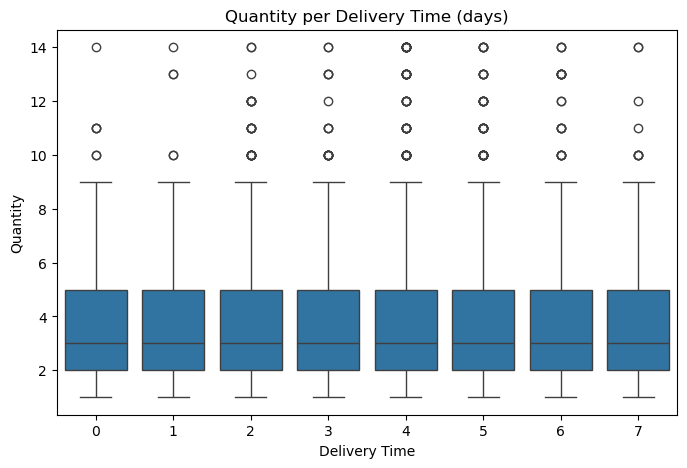

In [47]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Delivery Time", y="Quantity", data=df)
plt.title("Quantity per Delivery Time (days)")
plt.show()

There's no significant relation between the amount of products ordered and the delivery time. 

### Insights on the customers, grouped into: 
* High Quantity purchase customers
* Discount seekers
* High Profitable customers

What do these groups look like?
* Where are they located
* What do they buy

In [48]:
#First we define the groups

customer_summary = df.groupby("Customer ID").agg({
    "Quantity": "sum",
    "Discount": "mean",
    "Profit": "sum"
}).reset_index()

quantity_threshold = customer_summary["Quantity"].quantile(0.80)
profit_threshold = customer_summary["Profit"].quantile(0.80)
discount_threshold = customer_summary["Discount"].quantile(0.80)


In [49]:
customer_summary["High_Quantity"] = customer_summary["Quantity"] >= quantity_threshold
customer_summary["High_Profit"] = customer_summary["Profit"] >= profit_threshold
customer_summary["Discount_Seeker"] = customer_summary["Discount"] >= discount_threshold

print(customer_summary["High_Quantity"].value_counts())
print(customer_summary["High_Profit"].value_counts())
print(customer_summary["Discount_Seeker"].value_counts())

High_Quantity
False    631
True     162
Name: count, dtype: int64
High_Profit
False    634
True     159
Name: count, dtype: int64
Discount_Seeker
False    633
True     160
Name: count, dtype: int64


In [50]:
df_with_labels = df.merge(
    customer_summary[["Customer ID", "High_Quantity", "High_Profit", "Discount_Seeker"]],
    on="Customer ID",
    how="left"
)

df_with_labels.head(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Delivery Time,High_Quantity,High_Profit,Discount_Seeker
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,3,False,False,False
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820,3,False,False,False


In [67]:
hq_cust = df_with_labels[df_with_labels["High_Quantity"] == True]
topstate_hq = hq_cust.groupby("State")["Quantity"].sum().sort_values(ascending=False).head(10)
topsubcat_hq = hq_cust.groupby("Sub-Category")["Quantity"].sum().sort_values(ascending=False).head(10)

hp_cust = df_with_labels[df_with_labels["High_Profit"] == True]
topstate_hp = hp_cust.groupby("State")["Profit"].sum().sort_values(ascending=False).head(10)
topsubcat_hp = hp_cust.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(10)

ds_cust = df_with_labels[df_with_labels["Discount_Seeker"] == True]
topstate_ds = ds_cust.groupby("State")["Discount"].mean().sort_values(ascending=False).head(10)
topsubcat_ds = ds_cust.groupby("Sub-Category")["Discount"].mean().sort_values(ascending=False).head(10)

print(f"Top 10 states with highest quantity of orders: {topstate_hq}")
print(f"Top 10 Sub-Categories with highest quantity of orders: {topsubcat_hq}")

print(f"Top 10 states with highest profit: {topstate_hp}")
print(f"Top 10 Sub-Categories with highest profit: {topsubcat_hp}")

print(f"Top 10 states with highest discount: {topstate_ds}")
print(f"Top 10 Sub-Categories with highest discount: {topsubcat_ds}")



Top 10 states with highest quantity of orders: State
California      2926
Texas           1357
New York        1298
Pennsylvania     912
Illinois         686
Washington       652
Ohio             566
Florida          490
Michigan         425
Virginia         353
Name: Quantity, dtype: int64
Top 10 Sub-Categories with highest quantity of orders: Sub-Category
Binders        2136
Paper          1881
Furnishings    1311
Phones         1202
Storage        1168
Accessories    1132
Art            1056
Chairs          851
Appliances      637
Labels          519
Name: Quantity, dtype: int64
Top 10 states with highest profit: State
New York        45717.0229
California      38063.8434
Washington      20763.2114
Michigan        17400.8675
Indiana         13482.0659
Virginia        11814.8164
Georgia         10417.6381
Minnesota        8964.1106
Delaware         8117.4453
Rhode Island     6689.7125
Name: Profit, dtype: float64
Top 10 Sub-Categories with highest profit: Sub-Category
Copiers        

### The following graphs are just for the visuals, which will be used in the report

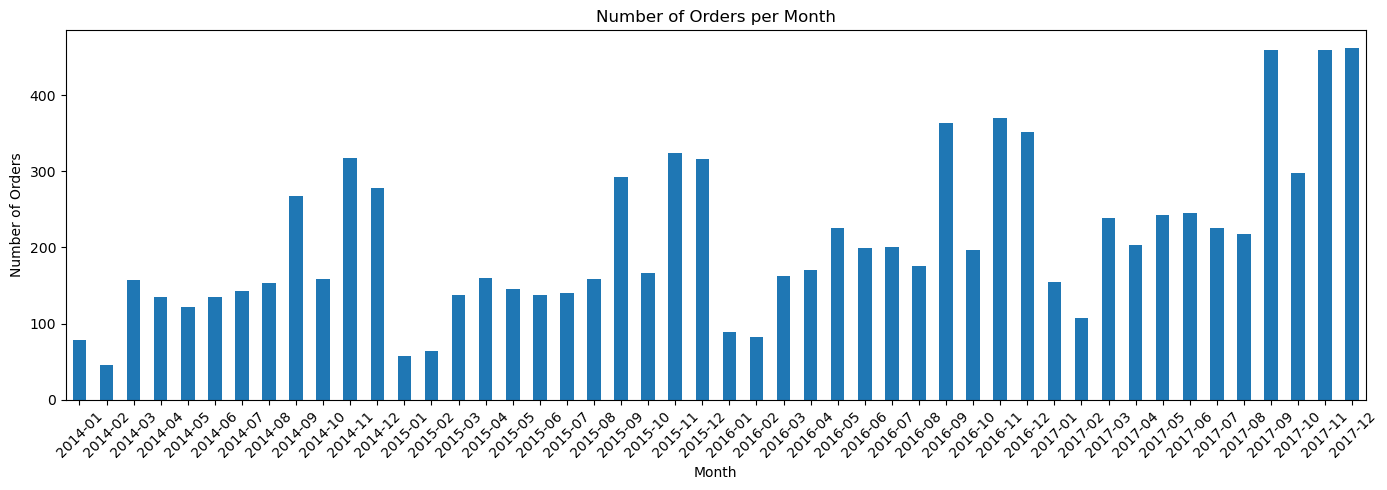

In [52]:
#timeframe of the dataset
df["Order Month"] = df["Order Date"].dt.to_period("M")

orders_per_month = df.groupby("Order Month").size()

plt.figure(figsize=(14, 5))
orders_per_month.plot(kind="bar")
plt.title("Number of Orders per Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

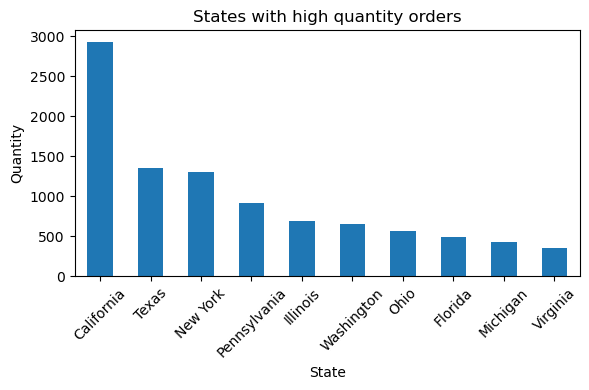

In [57]:
plt.figure(figsize=(6, 4))
topstate_hq.plot(kind="bar")
plt.title("States with high quantity orders")
plt.xlabel("State")
plt.ylabel("Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

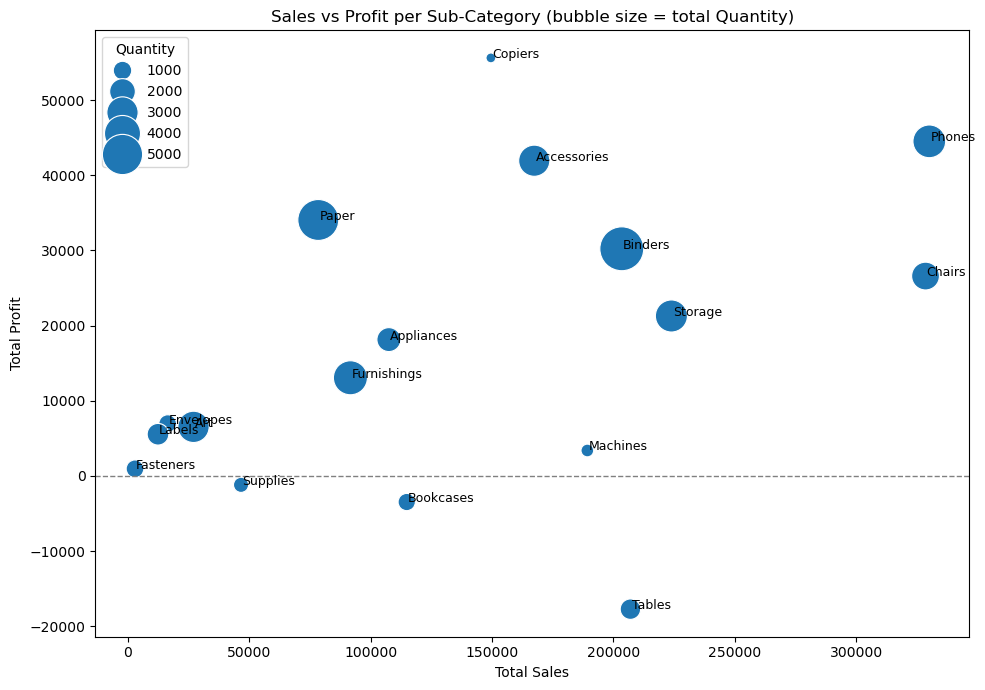

In [66]:
# Stap 1: totale Sales, Profit en Quantity per sub-category
subcat_summary = df.groupby("Sub-Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).reset_index()

# Stap 2: bubble chart met labels
plt.figure(figsize=(10, 7))
sns.scatterplot(data=subcat_summary, x="Sales", y="Profit", size="Quantity", sizes=(50, 1000), legend="brief")

for i in range(len(subcat_summary)):
    plt.text(
        subcat_summary["Sales"][i] + 500,
        subcat_summary["Profit"][i],
        subcat_summary["Sub-Category"][i],
        fontsize=9
    )

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.title("Sales vs Profit per Sub-Category (bubble size = total Quantity)")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()